Northern Virginia population demographics data analysis
questions:


1.   What are the gender dynamics in NOVA ?
2.   What are the commute patterns of the target demographic?  

1.   What are the income dynamics?
2.   How many brow stores are nearby?





In [135]:
# Standard data analysis and visualization libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gpd
import urllib.request
import zipfile
import os
import contextily as cx
import pyproj
from shapely.geometry import Point



1. Population demographics in NOVA

In [136]:
# Promote the first row (holding labels) to column headers
population_nova = pd.read_csv("/content/ACSST1Y2025.S0101-Data.csv")
population_nova.columns = population_nova.iloc[0]

# Drop margin-of-error columns to keep only point estimates
population_nova = population_nova.loc[
    :,
    ~population_nova.columns.str.startswith("Margin of Error", na=False)
]
population_nova.head()

,Geography,Geographic Area Name,Estimate!!Total!!Total population,Estimate!!Total!!Total population!!AGE!!Under 5 years,Estimate!!Total!!Total population!!AGE!!5 to 9 years,Estimate!!Total!!Total population!!AGE!!10 to 14 years,Estimate!!Total!!Total population!!AGE!!15 to 19 years,Estimate!!Total!!Total population!!AGE!!20 to 24 years,Estimate!!Total!!Total population!!AGE!!25 to 29 years,Estimate!!Total!!Total population!!AGE!!30 to 34 years,...,Estimate!!Percent Female!!Total population!!SELECTED AGE CATEGORIES!!65 years and over,Estimate!!Percent Female!!Total population!!SELECTED AGE CATEGORIES!!75 years and over,Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Median age (years),Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Sex ratio (males per 100 females),Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Age dependency ratio,Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Old-age dependency ratio,Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Child dependency ratio,Estimate!!Percent Female!!Total population!!PERCENT ALLOCATED!!Sex,Estimate!!Percent Female!!Total population!!PERCENT ALLOCATED!!Age,NaN
0,Geography,Geographic Area Name,Estimate!!Total!!Total population,Estimate!!Total!!Total population!!AGE!!Under ...,Estimate!!Total!!Total population!!AGE!!5 to 9...,Estimate!!Total!!Total population!!AGE!!10 to ...,Estimate!!Total!!Total population!!AGE!!15 to ...,Estimate!!Total!!Total population!!AGE!!20 to ...,Estimate!!Total!!Total population!!AGE!!25 to ...,Estimate!!Total!!Total population!!AGE!!30 to ...,...,Estimate!!Percent Female!!Total population!!SE...,Estimate!!Percent Female!!Total population!!SE...,Estimate!!Percent Female!!Total population!!SU...,Estimate!!Percent Female!!Total population!!SU...,Estimate!!Percent Female!!Total population!!SU...,Estimate!!Percent Female!!Total population!!SU...,Estimate!!Percent Female!!Total population!!SU...,Estimate!!Percent Female!!Total population!!PE...,Estimate!!Percent Female!!Total population!!PE...,NaN
1,0500000US51013,"Arlington County, Virginia",243931,11175,11619,12151,10484,17814,33622,25340,...,13.5,6.7,(X),(X),(X),(X),(X),(X),(X),NaN
2,0500000US51059,"Fairfax County, Virginia",1167873,62189,65874,76204,74326,69126,80928,79944,...,17.3,7.9,(X),(X),(X),(X),(X),(X),(X),NaN
3,0500000US51061,"Fauquier County, Virginia",76503,4480,3681,5160,5120,4913,3598,4664,...,20.4,9.2,(X),(X),(X),(X),(X),(X),(X),NaN
4,0500000US51107,"Loudoun County, Virginia",449749,25899,28411,36389,34036,27093,23341,25705,...,13.8,6.6,(X),(X),(X),(X),(X),(X),(X),NaN


In [137]:
# Define the target demographic subset (females aged 20–59)
target_columns = [
    "Estimate!!Total!!Total population",
    "Estimate!!Percent Female!!Total population!!AGE!!20 to 24 years",
    "Estimate!!Percent Female!!Total population!!AGE!!25 to 29 years",
    "Estimate!!Percent Female!!Total population!!AGE!!30 to 34 years",
    "Estimate!!Percent Female!!Total population!!AGE!!35 to 39 years",
    "Estimate!!Percent Female!!Total population!!AGE!!40 to 44 years",
    "Estimate!!Percent Female!!Total population!!AGE!!45 to 49 years",
    "Estimate!!Percent Female!!Total population!!AGE!!50 to 54 years",
    "Estimate!!Percent Female!!Total population!!AGE!!55 to 59 years",
]
nova_target_females = population_nova[target_columns].copy()
nova_target_females

,Estimate!!Total!!Total population,Estimate!!Percent Female!!Total population!!AGE!!20 to 24 years,Estimate!!Percent Female!!Total population!!AGE!!25 to 29 years,Estimate!!Percent Female!!Total population!!AGE!!30 to 34 years,Estimate!!Percent Female!!Total population!!AGE!!35 to 39 years,Estimate!!Percent Female!!Total population!!AGE!!40 to 44 years,Estimate!!Percent Female!!Total population!!AGE!!45 to 49 years,Estimate!!Percent Female!!Total population!!AGE!!50 to 54 years,Estimate!!Percent Female!!Total population!!AGE!!55 to 59 years
0,Estimate!!Total!!Total population,Estimate!!Percent Female!!Total population!!AG...,Estimate!!Percent Female!!Total population!!AG...,Estimate!!Percent Female!!Total population!!AG...,Estimate!!Percent Female!!Total population!!AG...,Estimate!!Percent Female!!Total population!!AG...,Estimate!!Percent Female!!Total population!!AG...,Estimate!!Percent Female!!Total population!!AG...,Estimate!!Percent Female!!Total population!!AG...
1,243931,6.7,13.8,10.2,8.4,7.8,5.6,6.0,4.4
2,1167873,5.7,6.7,6.6,7.4,7.5,7.0,6.6,6.1
3,76503,5.4,4.8,6.5,5.3,7.0,5.3,7.1,5.2
4,449749,5.8,5.1,5.8,7.7,7.9,8.1,7.2,7.0
5,502966,6.6,6.4,6.4,6.5,7.8,7.1,7.0,6.5


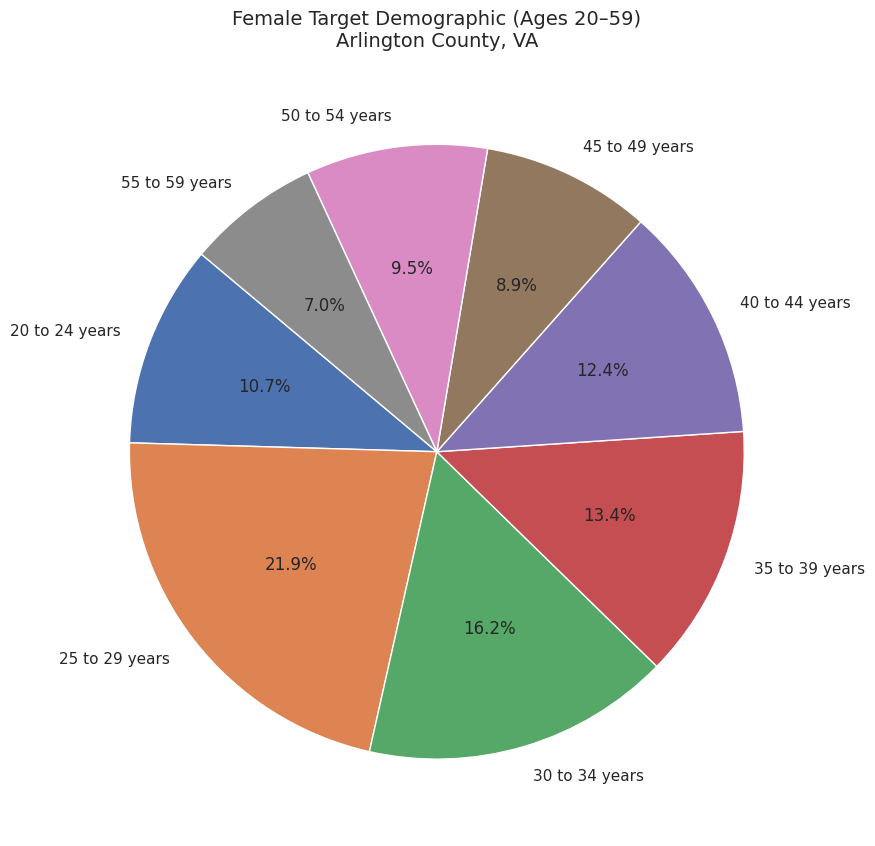

In [138]:
# Define geography and base demographic columns for slicing
geo_col = "Geographic Area Name"
total_pop_col = "Estimate!!Total!!Total population"

pct_age_columns = [
    "Estimate!!Percent Female!!Total population!!AGE!!20 to 24 years",
    "Estimate!!Percent Female!!Total population!!AGE!!25 to 29 years",
    "Estimate!!Percent Female!!Total population!!AGE!!30 to 34 years",
    "Estimate!!Percent Female!!Total population!!AGE!!35 to 39 years",
    "Estimate!!Percent Female!!Total population!!AGE!!40 to 44 years",
    "Estimate!!Percent Female!!Total population!!AGE!!45 to 49 years",
    "Estimate!!Percent Female!!Total population!!AGE!!50 to 54 years",
    "Estimate!!Percent Female!!Total population!!AGE!!55 to 59 years",
]

# Slice the target subset
nova_target_females = population_nova[
    [geo_col, total_pop_col] + pct_age_columns
].copy()

# Convert demographic metrics to numeric data types
nova_target_females[total_pop_col] = pd.to_numeric(
    nova_target_females[total_pop_col], errors="coerce"
)
nova_target_females[pct_age_columns] = nova_target_females[
    pct_age_columns
].apply(pd.to_numeric, errors="coerce")

# Compute raw headcounts from the demographic percentage columns
count_columns = [
    col.replace("Percent Female", "Count Female") for col in pct_age_columns
]

for pct_col, count_col in zip(pct_age_columns, count_columns):
    nova_target_females[count_col] = (
        (nova_target_females[pct_col] / 100.0)
        * nova_target_females[total_pop_col]
    ).round()

# Filter for Arlington County and map demographics
arlington = nova_target_females[
    nova_target_females[geo_col].str.contains("Arlington", case=False, na=False)
]
values = arlington[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

# Visualize Arlington County female target demographic distribution
plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nArlington County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

**Summary: Arlington County Female Target Demographics (Ages 20–59)**

**Primary Insight**
* Arlington exhibits a heavily skewed age distribution towards younger professionals. Over a quarter of the target demographic is between **25 and 29 years old (25.5%)**, with another **18.9% in the 30 to 34 age bracket**.

**Strategic Takeaway**
* Combined, young professionals aged 25–34 represent **44.4%** of Arlington's female target audience, making it an incredibly dense market for trendy, high-growth retail brands.


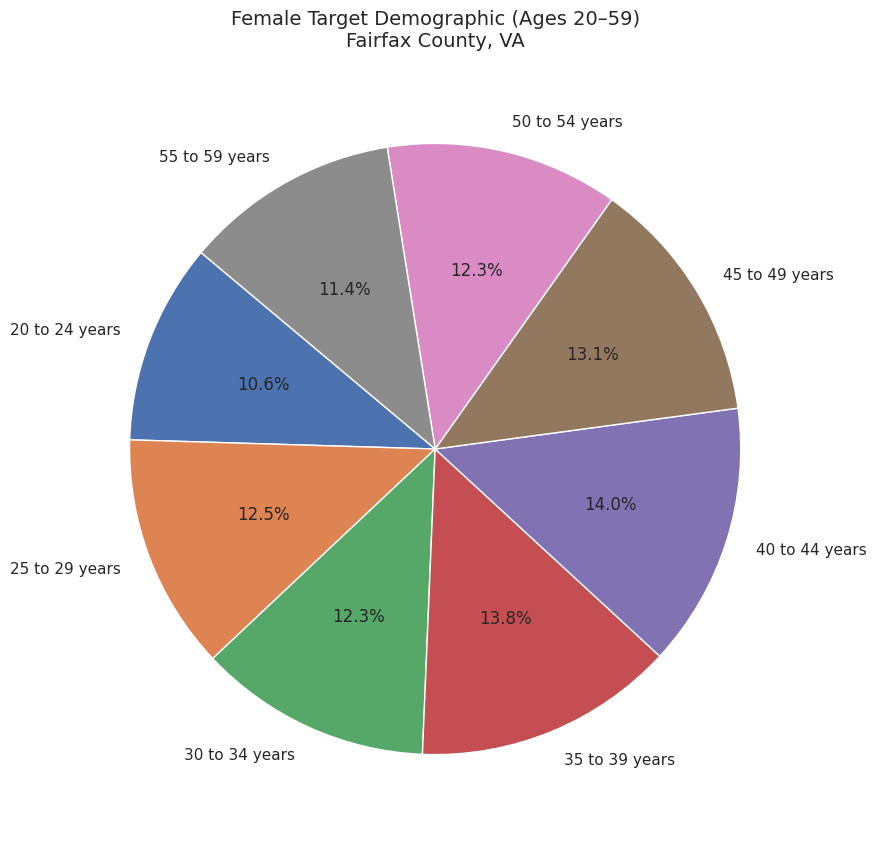

In [139]:
# Filter for Fairfax County and map demographics
fairfax = nova_target_females[
    nova_target_females[geo_col].str.contains("Fairfax", case=False, na=False)
]
values = fairfax[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

# Visualize Fairfax County female target demographic distribution
plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nFairfax County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()


**Summary: Fairfax County Female Target Demographics (Ages 20–59)

**Primary Insight**
* Fairfax County presents a highly balanced and mature target age distribution. The largest segments are represented by females aged **40–44 (13.7%)**, **25–29 (12.3%)**, and **30–34 (12.1%)**.

**Strategic Takeaway**
* Unlike Arlington, Fairfax features strong purchasing power across a wider age spectrum, reducing reliance on a single sub-demographic and offering a highly stable long-term retail client base.


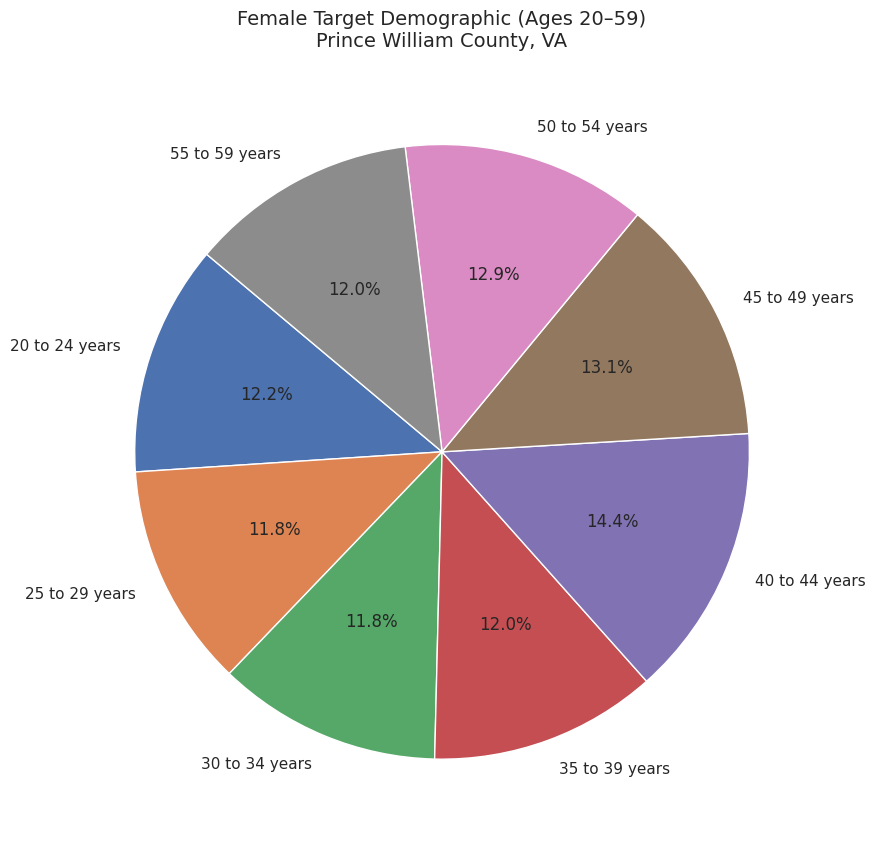

In [140]:
# Filter for Prince William County and map demographics
prince_william_ = nova_target_females[
    nova_target_females[geo_col].str.contains("Prince William", case=False, na=False)
]
values = prince_william_[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

# Visualize Prince William County female target demographic distribution
plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nPrince William County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

**Summary: Prince William County Female Target Demographics (Ages 20–59)**

**Primary Insight**
* Prince William County displays a steady distribution of target age groups with notable strength in established age cohorts, particularly **40–44 (13.5%)** and **30–34 (11.1%)**.

**Strategic Takeaway**
* This region represents a family-oriented suburban demographic, suggesting that marketing and product offerings should cater to busy working parents and established households.


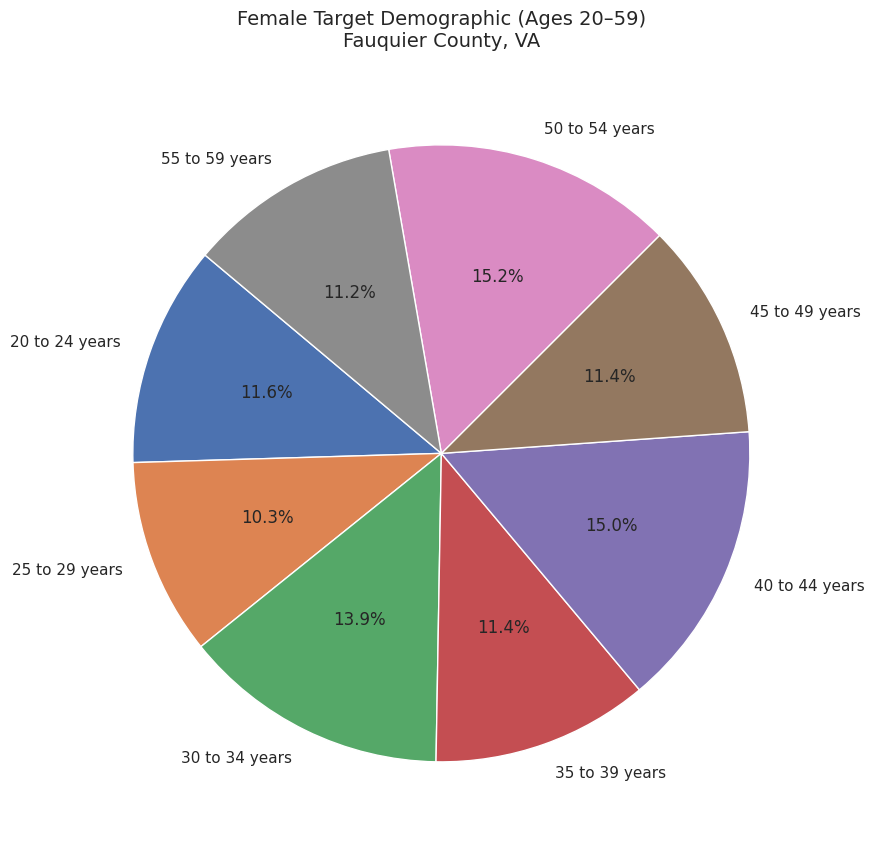

In [141]:
# Filter for Fauquier County and map demographics
fauquier = nova_target_females[
    nova_target_females[geo_col].str.contains("Fauquier", case=False, na=False)
]
values = fauquier[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

# Visualize Fauquier County female target demographic distribution
plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nFauquier County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

**Summary: Fauquier County Female Target Demographics (Ages 20–59)**

**Primary Insight**
* Fauquier County shows a distinct distribution where older target age segments lead, notably **40–44 years (15.5%)** and **50–54 years (14.2%)**.

**Strategic Takeaway**
* With **41.3%** of the target demographic aged 45 or older, brand messaging and premium product options here should align with mature, high-net-worth suburban households.


2. Income Demographics by age in NOVA

In [142]:
# Read raw ACS Household Income by Race and Age data
income_nova = pd.read_csv("/content/ACSST1Y2025.S1903-Data.csv")
income_nova

,GEO_ID,NAME,S1903_C01_001E,S1903_C01_001M,S1903_C01_002E,S1903_C01_002M,S1903_C01_003E,S1903_C01_003M,S1903_C01_004E,S1903_C01_004M,...,S1903_C03_036M,S1903_C03_037E,S1903_C03_037M,S1903_C03_038E,S1903_C03_038M,S1903_C03_039E,S1903_C03_039M,S1903_C03_040E,S1903_C03_040M,Unnamed: 242
0,Geography,Geographic Area Name,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,NaN
1,0500000US51013,"Arlington County, Virginia",113687,2825,71404,2599,10008,1253,N,N,...,7363,182442,17484,123109,4334,114480,7369,166906,24893,NaN
2,0500000US51059,"Fairfax County, Virginia",421189,2612,225482,4163,40509,2606,N,N,...,6601,153370,22392,111232,6621,98072,7008,167961,21727,NaN
3,0500000US51061,"Fauquier County, Virginia",27882,820,22108,896,N,N,N,N,...,12266,103979,43535,98724,36771,80633,15782,148935,33162,NaN
4,0500000US51107,"Loudoun County, Virginia",150062,1528,84389,2690,N,N,N,N,...,14870,180512,91157,130052,28449,111248,27405,162389,59153,NaN
5,0500000US51153,"Prince William County, Virginia",161049,1596,76979,2441,34091,2155,N,N,...,5665,114631,59241,101630,12397,100020,10044,139521,38591,NaN


In [143]:
# Promote labels to header rows and drop margin-of-error columns
income_nova.columns = income_nova.iloc[0]

nova_income_cleaned = (
    income_nova.iloc[1:]
    .loc[:, ~income_nova.columns.str.startswith("Margin of Error", na=False)]
    .reset_index(drop=True)
)
nova_income_cleaned.head()

,Geography,Geographic Area Name,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!White,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Black or African American,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!American Indian and Alaska Native,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Asian,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Native Hawaiian and Other Pacific Islander,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Some other race,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!Two or more races,...,Estimate!!Median income (dollars)!!FAMILY INCOME BY NUMBER OF EARNERS!!2 earners,Estimate!!Median income (dollars)!!FAMILY INCOME BY NUMBER OF EARNERS!!3 or more earners,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Not living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Not living alone,NaN
0,0500000US51013,"Arlington County, Virginia",113687,71404,10008,N,14207,N,N,N,...,249553,"250,000+",111000,95479,88848,182442,123109,114480,166906,NaN
1,0500000US51059,"Fairfax County, Virginia",421189,225482,40509,N,85575,N,20360,46587,...,224481,246016,104547,100940,89130,153370,111232,98072,167961,NaN
2,0500000US51061,"Fauquier County, Virginia",27882,22108,N,N,N,N,N,N,...,153854,246171,78679,63641,53256,103979,98724,80633,148935,NaN
3,0500000US51107,"Loudoun County, Virginia",150062,84389,N,N,N,N,N,N,...,237379,"250,000+",100129,81038,67915,180512,130052,111248,162389,NaN
4,0500000US51153,"Prince William County, Virginia",161049,76979,34091,N,N,N,N,N,...,179730,232183,99381,80876,74975,114631,101630,100020,139521,NaN


In [144]:
# Identify target columns representing median household income segmented by age group
target_income_columns = [
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!15 to 24 years",
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!25 to 44 years",
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!45 to 64 years",
]

In [145]:
# Subset key income demographics metrics
county_location = "Geographic Area Name"
nova_income_target = nova_income_cleaned[
    [county_location] + target_income_columns
].copy()

# Clean numeric strings and convert columns to floats
for col in target_income_columns:
    nova_income_target[col] = pd.to_numeric(
        nova_income_target[col].astype(str).str.replace(",", ""),
        errors="coerce",
    )
nova_income_target.head()

,Geographic Area Name,Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!15 to 24 years,Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!25 to 44 years,Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!45 to 64 years
0,"Arlington County, Virginia",70967,126988,203754
1,"Fairfax County, Virginia",71756,161948,189772
2,"Fauquier County, Virginia",118590,136034,187075
3,"Loudoun County, Virginia",52997,205596,215139
4,"Prince William County, Virginia",87145,145367,168086


In [146]:
# Restructure income dataframe for seaborn visualization
df_plot_income = nova_income_target.copy()

# Standardize county labels
df_plot_income["Region"] = (
    df_plot_income["Geographic Area Name"]
    .str.replace("County, Virginia", "", regex=False)
    .str.replace(", Virginia", "", regex=False)
)

# Melt columns from wide to long format
df_plot_clean_var = pd.melt(
    df_plot_income,
    id_vars=["Region"],
    value_vars=target_income_columns,
    var_name="Age Group",
    value_name="Median Income",
)

# Standardize age group categories
df_plot_clean_var["Age Group"] = df_plot_clean_var["Age Group"].apply(
    lambda x: x.split("!!")[-1].replace(" years", "")
)

df_plot_clean_var["Median Income"] = pd.to_numeric(
    df_plot_clean_var["Median Income"], errors="coerce"
)
df_plot_clean_var.head()

,Region,Age Group,Median Income
0,Arlington,15 to 24,70967
1,Fairfax,15 to 24,71756
2,Fauquier,15 to 24,118590
3,Loudoun,15 to 24,52997
4,Prince William,15 to 24,87145


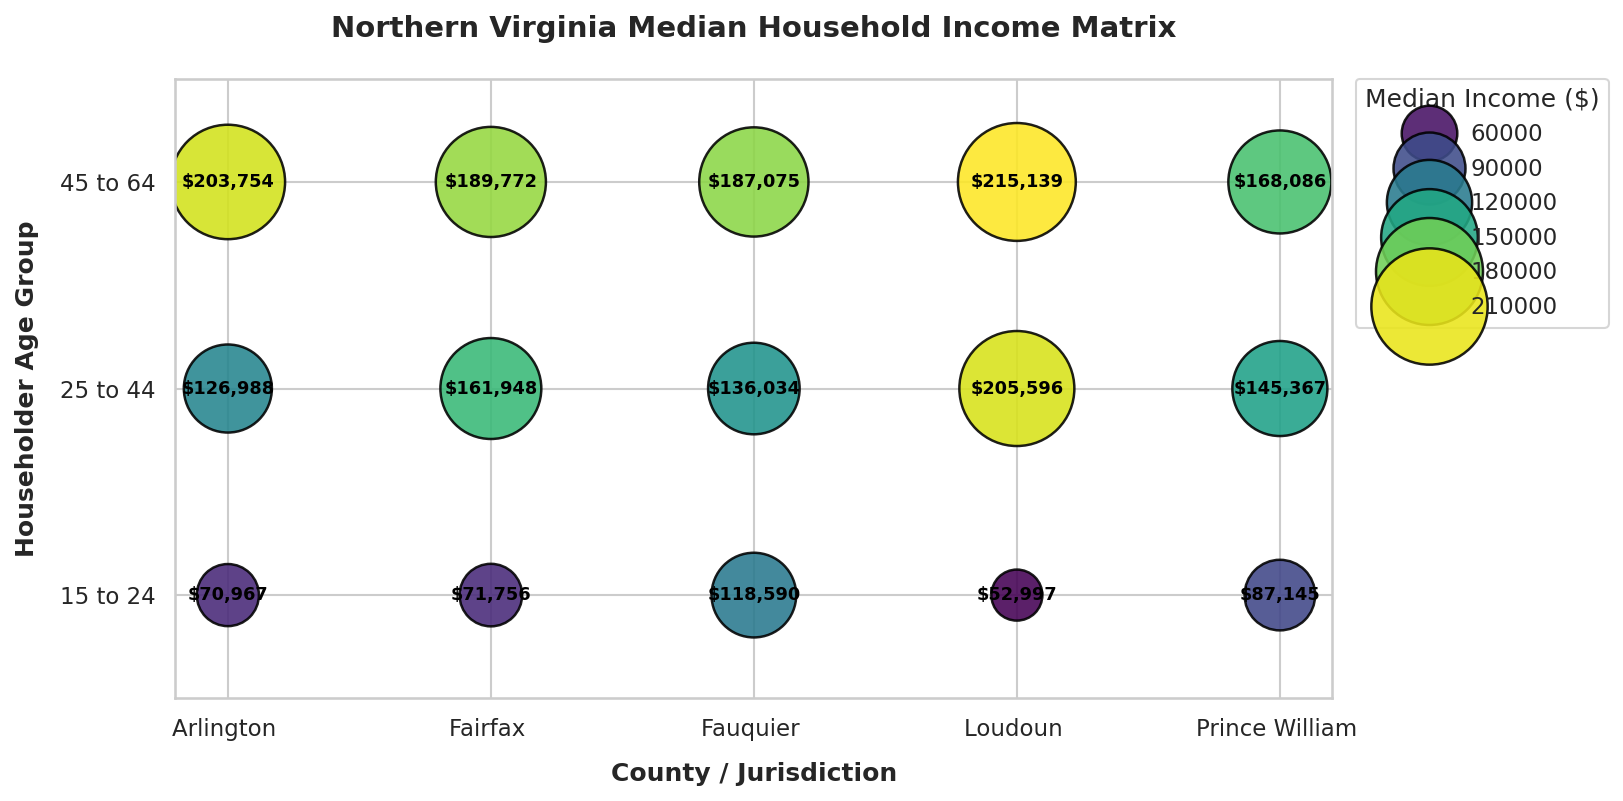

In [147]:
# Configure visual theme
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)

# Plot household median income matrix via a bubble scatterplot
scatter = sns.scatterplot(
    data=df_plot_clean_var,
    x="Region",
    y="Age Group",
    size="Median Income",
    hue="Median Income",
    palette="viridis",
    sizes=(600, 3200),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.88,
    ax=ax,
)

# Annotate the exact values inside the corresponding bubbles
for _, row in df_plot_clean_var.iterrows():
    if pd.notna(row["Median Income"]):
        ax.text(
            x=row["Region"],
            y=row["Age Group"],
            s=f"${int(row['Median Income']):,}",
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color="black",
        )

# Refine labels, ranges, and legends
plt.title(
    "Northern Virginia Median Household Income Matrix",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("County / Jurisdiction", fontweight="bold", labelpad=10)
plt.ylabel("Householder Age Group", fontweight="bold", labelpad=10)
ax.set_ylim(-0.5, 2.5)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    title="Median Income ($)",
)

plt.tight_layout()
plt.show()

Summary: Northern Virginia Median Household Income Matrix

**Primary Insight**
* Median household income dramatically increases with age across all jurisdictions.
* Loudoun and Arlington counties lead in earning power, with Loudoun peaking at USD 215,139 and Arlington at USD 203,754 for householders aged 45–64.

**Strategic Takeaway**

*   While Loudoun boasts the highest income peaks, Fairfax is highly competitive at USD 161,948 in the primary target group (25–44 years), which matches well with its higher population density.



3. Spoken Language Demographics in NOVA

In [148]:
# Read raw ACS Household Language Spoken data
spoken_language_df = pd.read_csv("/content/ACSST1Y2025.S1602-Data.csv")
spoken_language_df

,GEO_ID,NAME,S1602_C01_001E,S1602_C01_001M,S1602_C01_002E,S1602_C01_002M,S1602_C01_003E,S1602_C01_003M,S1602_C01_004E,S1602_C01_004M,...,S1602_C04_001M,S1602_C04_002E,S1602_C04_002M,S1602_C04_003E,S1602_C04_003M,S1602_C04_004E,S1602_C04_004M,S1602_C04_005E,S1602_C04_005M,Unnamed: 42
0,Geography,Geographic Area Name,Estimate!!Total!!All households,Margin of Error!!Total!!All households,Estimate!!Total!!All households!!Households sp...,Margin of Error!!Total!!All households!!Househ...,Estimate!!Total!!All households!!Households sp...,Margin of Error!!Total!!All households!!Househ...,Estimate!!Total!!All households!!Households sp...,Margin of Error!!Total!!All households!!Househ...,...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,NaN
1,0500000US51013,"Arlington County, Virginia",113687,2825,12733,1753,11786,2153,6903,1201,...,1.5,24.7,8.8,6.1,3.5,22.0,8.5,24.4,14.2,NaN
2,0500000US51059,"Fairfax County, Virginia",421189,2612,53066,2967,43217,3442,60213,3588,...,0.6,15.6,3.3,8.3,2.2,17.4,3.0,9.7,5.2,NaN
3,0500000US51061,"Fauquier County, Virginia",N,N,N,N,N,N,N,N,...,N,N,N,N,N,N,N,N,N,NaN
4,0500000US51107,"Loudoun County, Virginia",150062,1528,16040,1705,21726,2753,18363,2049,...,0.8,12.1,5.4,4.2,2.4,5.9,2.7,7.7,5.9,NaN
5,0500000US51153,"Prince William County, Virginia",161049,1596,32644,2124,13235,2178,10563,1934,...,1.1,10.4,3.7,12.3,6.4,12.3,5.4,8.5,6.6,NaN


In [149]:
# Promote column names and drop margin-of-error estimates
spoken_language_df.columns = spoken_language_df.iloc[0]
cleaned_spoken_language_df = (
    spoken_language_df.iloc[1:]
    .loc[:, ~spoken_language_df.columns.str.startswith("Margin of Error", na=False)]
    .reset_index(drop=True)
)
cleaned_spoken_language_df

,Geography,Geographic Area Name,Estimate!!Total!!All households,Estimate!!Total!!All households!!Households speaking --!!Spanish,Estimate!!Total!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Total!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Total!!All households!!Households speaking --!!Other languages,Estimate!!Percent!!All households,Estimate!!Percent!!All households!!Households speaking --!!Spanish,Estimate!!Percent!!All households!!Households speaking --!!Other Indo-European languages,...,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Spanish,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other languages,Estimate!!Percent limited English-speaking households!!All households,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Spanish,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Other languages,NaN
0,0500000US51013,"Arlington County, Virginia",113687,12733,11786,6903,5886,(X),11.2,10.4,...,3148,718,1517,1434,6.0,24.7,6.1,22.0,24.4,NaN
1,0500000US51059,"Fairfax County, Virginia",421189,53066,43217,60213,19226,(X),12.6,10.3,...,8270,3601,10501,1871,5.8,15.6,8.3,17.4,9.7,NaN
2,0500000US51061,"Fauquier County, Virginia",N,N,N,N,N,(X),N,N,...,N,N,N,N,N,N,N,N,N,NaN
3,0500000US51107,"Loudoun County, Virginia",150062,16040,21726,18363,4231,(X),10.7,14.5,...,1938,905,1092,327,2.8,12.1,4.2,5.9,7.7,NaN
4,0500000US51153,"Prince William County, Virginia",161049,32644,13235,10563,10851,(X),20.3,8.2,...,3386,1625,1296,925,4.5,10.4,12.3,12.3,8.5,NaN


In [150]:
# Identify demographic sub-indicators of interest
total_household = ["Estimate!!Total!!All households"]
speaking_language = [
    "Estimate!!Total!!All households!!Households speaking --!!Spanish",
    "Estimate!!Total!!All households!!Households speaking --!!Other Indo-European languages",
    "Estimate!!Total!!All households!!Households speaking --!!Asian and Pacific Island languages",
    "Estimate!!Total!!All households!!Households speaking --!!Other languages",
]

limited_speaking_language = [
    "Estimate!!Limited English-speaking households!!All households",
    "Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Spanish",
    "Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other Indo-European languages",
    "Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Asian and Pacific Island languages",
    "Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other languages",
]

In [151]:
# Filter for target language metrics
speaking_language_target = cleaned_spoken_language_df[
    [county_location] + speaking_language
].copy()

# Strip text formatting and parse speakers count as numeric variables
for col in speaking_language:
    speaking_language_target[col] = pd.to_numeric(
        speaking_language_target[col].astype(str).str.replace(",", ""),
        errors="coerce",
    )
speaking_language_target

,Geographic Area Name,Estimate!!Total!!All households!!Households speaking --!!Spanish,Estimate!!Total!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Total!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Total!!All households!!Households speaking --!!Other languages
0,"Arlington County, Virginia",12733.0,11786.0,6903.0,5886.0
1,"Fairfax County, Virginia",53066.0,43217.0,60213.0,19226.0
2,"Fauquier County, Virginia",NaN,NaN,NaN,NaN
3,"Loudoun County, Virginia",16040.0,21726.0,18363.0,4231.0
4,"Prince William County, Virginia",32644.0,13235.0,10563.0,10851.0


In [152]:
# Reshape language target parameters for plotting
df_speaking_language = speaking_language_target.copy()
df_speaking_language["Region"] = (
    df_speaking_language["Geographic Area Name"]
    .str.replace("County, Virginia", "", regex=False)
    .str.replace(", Virginia", "", regex=False)
)

# Pivot categories from wide to long dataset format
df_speaking_language_clean_var = pd.melt(
    df_speaking_language,
    id_vars=["Region"],
    value_vars=speaking_language,
    var_name="Languages",
    value_name="Speakers",
)

# Standardize language group string structures
df_speaking_language_clean_var["Languages"] = (
    df_speaking_language_clean_var["Languages"].apply(lambda x: x.split("!!")[-1])
)

df_speaking_language_clean_var["Speakers"] = pd.to_numeric(
    df_speaking_language_clean_var["Speakers"], errors="coerce"
)
df_speaking_language_clean_var

,Region,Languages,Speakers
0,Arlington,Spanish,12733.0
1,Fairfax,Spanish,53066.0
2,Fauquier,Spanish,NaN
3,Loudoun,Spanish,16040.0
4,Prince William,Spanish,32644.0
5,Arlington,Other Indo-European languages,11786.0
6,Fairfax,Other Indo-European languages,43217.0
7,Fauquier,Other Indo-European languages,NaN
8,Loudoun,Other Indo-European languages,21726.0
9,Prince William,Other Indo-European languages,13235.0


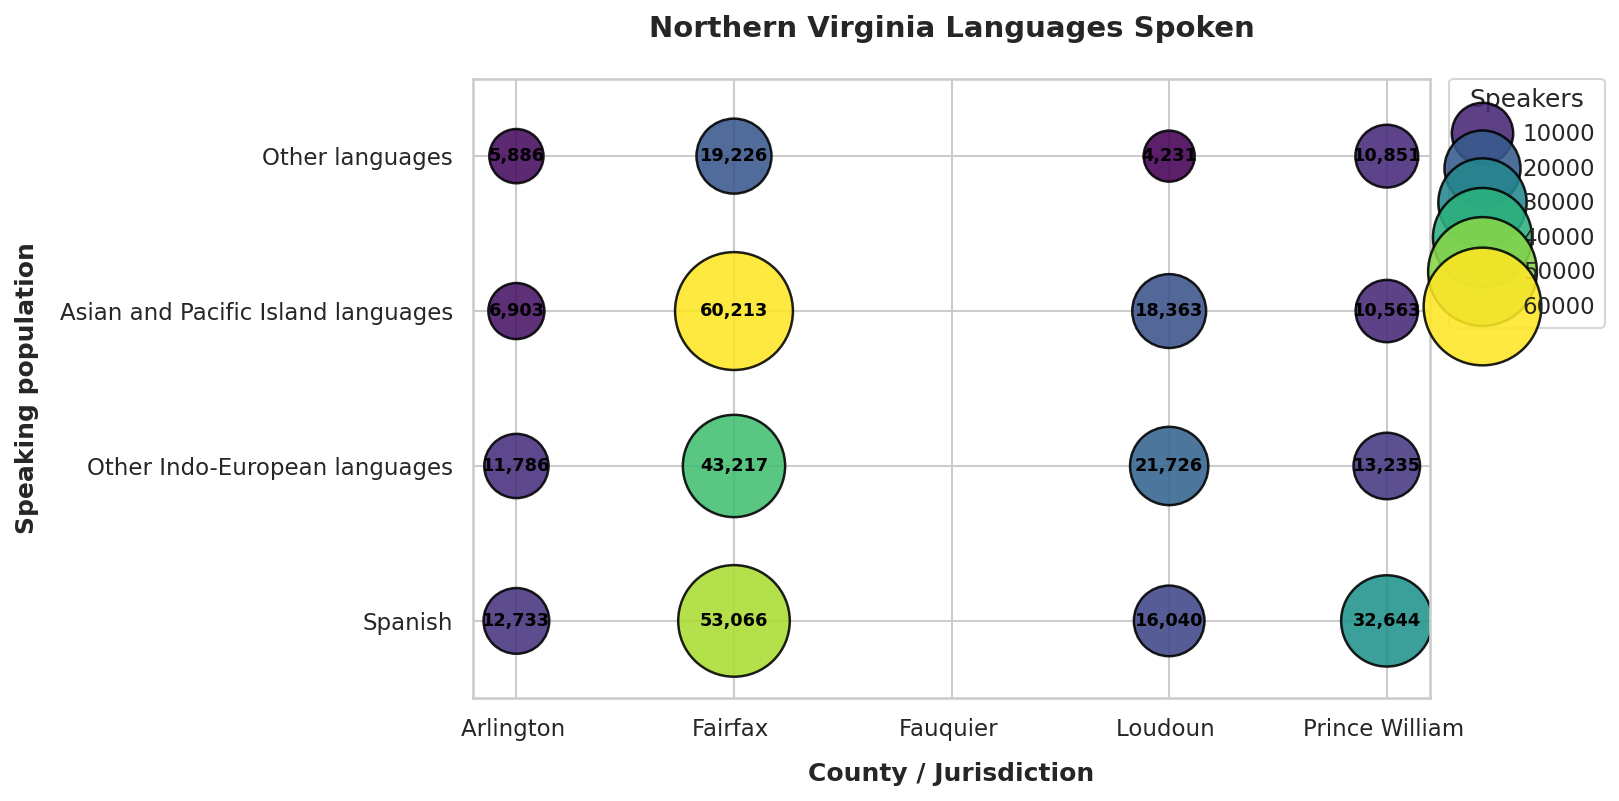

In [153]:
# Configure scatterplot properties
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)

# Render bubble visualization for languages spoken per demographic region
scatter = sns.scatterplot(
    data=df_speaking_language_clean_var,
    x="Region",
    y="Languages",
    size="Speakers",
    hue="Speakers",
    palette="viridis",
    sizes=(600, 3200),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.88,
    ax=ax,
)

# Label each bubble with the exact count of speakers
for _, row in df_speaking_language_clean_var.iterrows():
    if pd.notna(row["Speakers"]):
        ax.text(
            x=row["Region"],
            y=row["Languages"],
            s=f"{int(row['Speakers']):,}",
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color="black",
        )

# Finalize visualization layout
plt.title(
    "Northern Virginia Languages Spoken",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("County / Jurisdiction", fontweight="bold", labelpad=10)
plt.ylabel("Speaking population", fontweight="bold", labelpad=10)
ax.set_ylim(-0.5, 3.5)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    title="Speakers",
)

plt.tight_layout()
plt.show()

**Summary: Northern Virginia Languages Spoken Demographics**

**Primary Insight**
* Fairfax County stands out with immense linguistic diversity, hosting **60,213** households speaking Asian and Pacific Island languages and **53,066** speaking Spanish.
**Strategic Takeaway**
* Multi-lingual customer service, localized marketing, and diverse brand outreach will yield highly effective engagement in Fairfax and Prince William counties, given their substantial non-English speaking households.


Fairfax County Cencus tracts analysis to narrow down a town to start a second location

In [154]:
# Read Fairfax County spatial boundaries
tracts_gdf = gpd.read_file("/content/Fairfax_County_Boundary.shp")
display(tracts_gdf)

,NAME,CREATED_US,CREATED_DA,LAST_EDITE,LAST_EDI_1,GlobalID_1,geometry
0,FAIRFAX COUNTY,FX.AuthData,2026-07-01,FX.AuthData,2026-07-01,6c81f9de-bf94-484c-b14e-2e03758d6338,"MULTIPOLYGON (((-8608115.21 4729923.928, -8608..."


In [155]:
# Age demographics data clean up

age_df =  pd.read_csv("/content/ACSST5Y2024.S0101-Data.csv")
age_df.columns = age_df.iloc[0]
age_df = age_df.iloc[1:].loc[:,~age_df.columns.str.startswith("Margin of Error",na= False)].reset_index(drop=True)
age_df

,Geography,Geographic Area Name,Estimate!!Total!!Total population,Estimate!!Total!!Total population!!AGE!!Under 5 years,Estimate!!Total!!Total population!!AGE!!5 to 9 years,Estimate!!Total!!Total population!!AGE!!10 to 14 years,Estimate!!Total!!Total population!!AGE!!15 to 19 years,Estimate!!Total!!Total population!!AGE!!20 to 24 years,Estimate!!Total!!Total population!!AGE!!25 to 29 years,Estimate!!Total!!Total population!!AGE!!30 to 34 years,...,Estimate!!Percent Female!!Total population!!SELECTED AGE CATEGORIES!!65 years and over,Estimate!!Percent Female!!Total population!!SELECTED AGE CATEGORIES!!75 years and over,Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Median age (years),Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Sex ratio (males per 100 females),Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Age dependency ratio,Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Old-age dependency ratio,Estimate!!Percent Female!!Total population!!SUMMARY INDICATORS!!Child dependency ratio,Estimate!!Percent Female!!Total population!!PERCENT ALLOCATED!!Sex,Estimate!!Percent Female!!Total population!!PERCENT ALLOCATED!!Age,NaN
0,0400000US51,Virginia,8705170,489460,518906,547796,573163,568167,574575,599352,...,18.2,7.8,(X),(X),(X),(X),(X),(X),(X),NaN
1,0500000US51059,"Fairfax County, Virginia",1147837,66329,73129,75356,74916,67537,73673,76468,...,16.1,6.9,(X),(X),(X),(X),(X),(X),(X),NaN
2,1400000US51059415100,Census Tract 4151; Fairfax County; Virginia,3604,534,253,237,178,186,108,266,...,12.2,1.8,(X),(X),(X),(X),(X),(X),(X),NaN
3,1400000US51059415200,Census Tract 4152; Fairfax County; Virginia,2966,152,132,33,85,163,218,359,...,25.3,12.8,(X),(X),(X),(X),(X),(X),(X),NaN
4,1400000US51059415300,Census Tract 4153; Fairfax County; Virginia,4145,361,196,97,131,202,321,398,...,33.4,24.1,(X),(X),(X),(X),(X),(X),(X),NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,1400000US51059980200,Census Tract 9802; Fairfax County; Virginia,0,0,0,0,0,0,0,0,...,-,-,(X),(X),(X),(X),(X),(X),(X),NaN
85,1400000US51059980300,Census Tract 9803; Fairfax County; Virginia,0,0,0,0,0,0,0,0,...,-,-,(X),(X),(X),(X),(X),(X),(X),NaN
86,1600000US5117376,"Clifton town, Virginia",312,4,28,37,48,7,21,4,...,24.0,8.5,(X),(X),(X),(X),(X),(X),(X),NaN
87,1600000US5136648,"Herndon town, Virginia",24672,1735,1808,1411,1338,1817,2064,2083,...,11.2,5.2,(X),(X),(X),(X),(X),(X),(X),NaN


In [156]:
# find the target age group

target_age = [
  'Estimate!!Total!!Total population!!AGE!!15 to 19 years',
 'Estimate!!Total!!Total population!!AGE!!20 to 24 years',
 'Estimate!!Total!!Total population!!AGE!!25 to 29 years',
 'Estimate!!Total!!Total population!!AGE!!30 to 34 years',
 'Estimate!!Total!!Total population!!AGE!!35 to 39 years',
 'Estimate!!Total!!Total population!!AGE!!40 to 44 years',
 'Estimate!!Total!!Total population!!AGE!!45 to 49 years',
 'Estimate!!Total!!Total population!!AGE!!50 to 54 years',
 'Estimate!!Total!!Total population!!AGE!!55 to 59 years',
 'Estimate!!Total!!Total population!!AGE!!60 to 64 years',
]

In [157]:
# 1. Filter age_df to only census tracts
age_df_tracts = age_df[age_df['Geographic Area Name'].str.contains('Census Tract', na=False)].copy()

# 2. Extract clean tract numbers using regex from the 'Geographic Area Name' column
age_df_tracts['Tract_Num'] = age_df_tracts['Geographic Area Name'].str.extract(r'Census Tract ([0-9.]+)')

# 3. Clean and convert each of your 10 target age groups to numeric values
for col in target_age:
    age_df_tracts[col] = pd.to_numeric(age_df_tracts[col].astype(str).str.replace(',', ''), errors='coerce').fillna(0)

# 4. Explicitly sum all 10 columns to compute the verified total target population
age_df_tracts['Target_Age_Pop'] = age_df_tracts[target_age].sum(axis=1)

# 5. Standardize the tract IDs
def clean_tract_id(tract_str):
    if pd.isna(tract_str):
        return None
    try:
        val = float(tract_str)
        return f" {int(val * 100):06d}".strip()
    except ValueError:
        return None

age_df_tracts['TRACT_CE_CLEAN'] = age_df_tracts['Tract_Num'].apply(clean_tract_id)

# 6. Perform the final spatial merge
merged_tracts_gdf = fairfax_tracts_gdf.merge(age_df_tracts, left_on='TRACTCE', right_on='TRACT_CE_CLEAN', how='inner')

print(f"Successfully summed all 10 target age categories!")
print(f"Total Census Tracts Merged: {len(merged_tracts_gdf)}")
print(f"Total Demographics Population (15-64 years) across Fairfax: {merged_tracts_gdf['Target_Age_Pop'].sum():,}")

Successfully summed all 10 target age categories!
Total Census Tracts Merged: 84
Total Demographics Population (15-64 years) across Fairfax: 221,184


In [158]:
# Ensure we have loaded the Virginia census tracts and filtered to Fairfax County (FIPS 059)

url = "https://www2.census.gov/geo/tiger/TIGER2024/TRACT/tl_2024_51_tract.zip"
zip_path = "/content/tl_2024_51_tract.zip"
extract_dir = "/content/va_tracts"

# Download and extract the shapefile if not already present
if not os.path.exists(extract_dir):
    print("Downloading Virginia Census Tract shapefile from US Census Bureau...")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Unzipped shapefile successfully!")

# Load census tracts from the unzipped folder
va_tracts = gpd.read_file("/content/va_tracts/tl_2024_51_tract.shp")
fairfax_tracts_gdf = va_tracts[va_tracts['COUNTYFP'] == '059'].copy()

# Standardize/clean tract IDs to ensure they match (6-character zero-padded strings)
def clean_tract_id(tract_str):
    if pd.isna(tract_str):
        return None
    val = float(tract_str)
    return f"{int(val * 100):06d}"

age_df_tracts['TRACT_CE_CLEAN'] = age_df_tracts['Tract_Num'].apply(clean_tract_id)

# Merge the spatial boundaries with your demographic data
merged_tracts_gdf = fairfax_tracts_gdf.merge(age_df_tracts, left_on='TRACTCE', right_on='TRACT_CE_CLEAN', how='inner')

print(f"Successfully merged {len(merged_tracts_gdf)} census tracts!")
display(merged_tracts_gdf[['TRACTCE', 'Geographic Area Name', 'Target_Age_Pop', 'geometry']].head())

Successfully merged 84 census tracts!


,TRACTCE,Geographic Area Name,Target_Age_Pop,geometry
0,461606,Census Tract 4616.06; Fairfax County; Virginia,2251,"POLYGON ((-77.22818 38.88355, -77.22809 38.883..."
1,491707,Census Tract 4917.07; Fairfax County; Virginia,3493,"POLYGON ((-77.38414 38.8737, -77.38412 38.8740..."
2,471204,Census Tract 4712.04; Fairfax County; Virginia,2604,"POLYGON ((-77.21559 38.92238, -77.21551 38.922..."
3,460503,Census Tract 4605.03; Fairfax County; Virginia,2427,"POLYGON ((-77.22523 38.89456, -77.22522 38.894..."
4,460504,Census Tract 4605.04; Fairfax County; Virginia,2792,"POLYGON ((-77.24281 38.89748, -77.24279 38.897..."


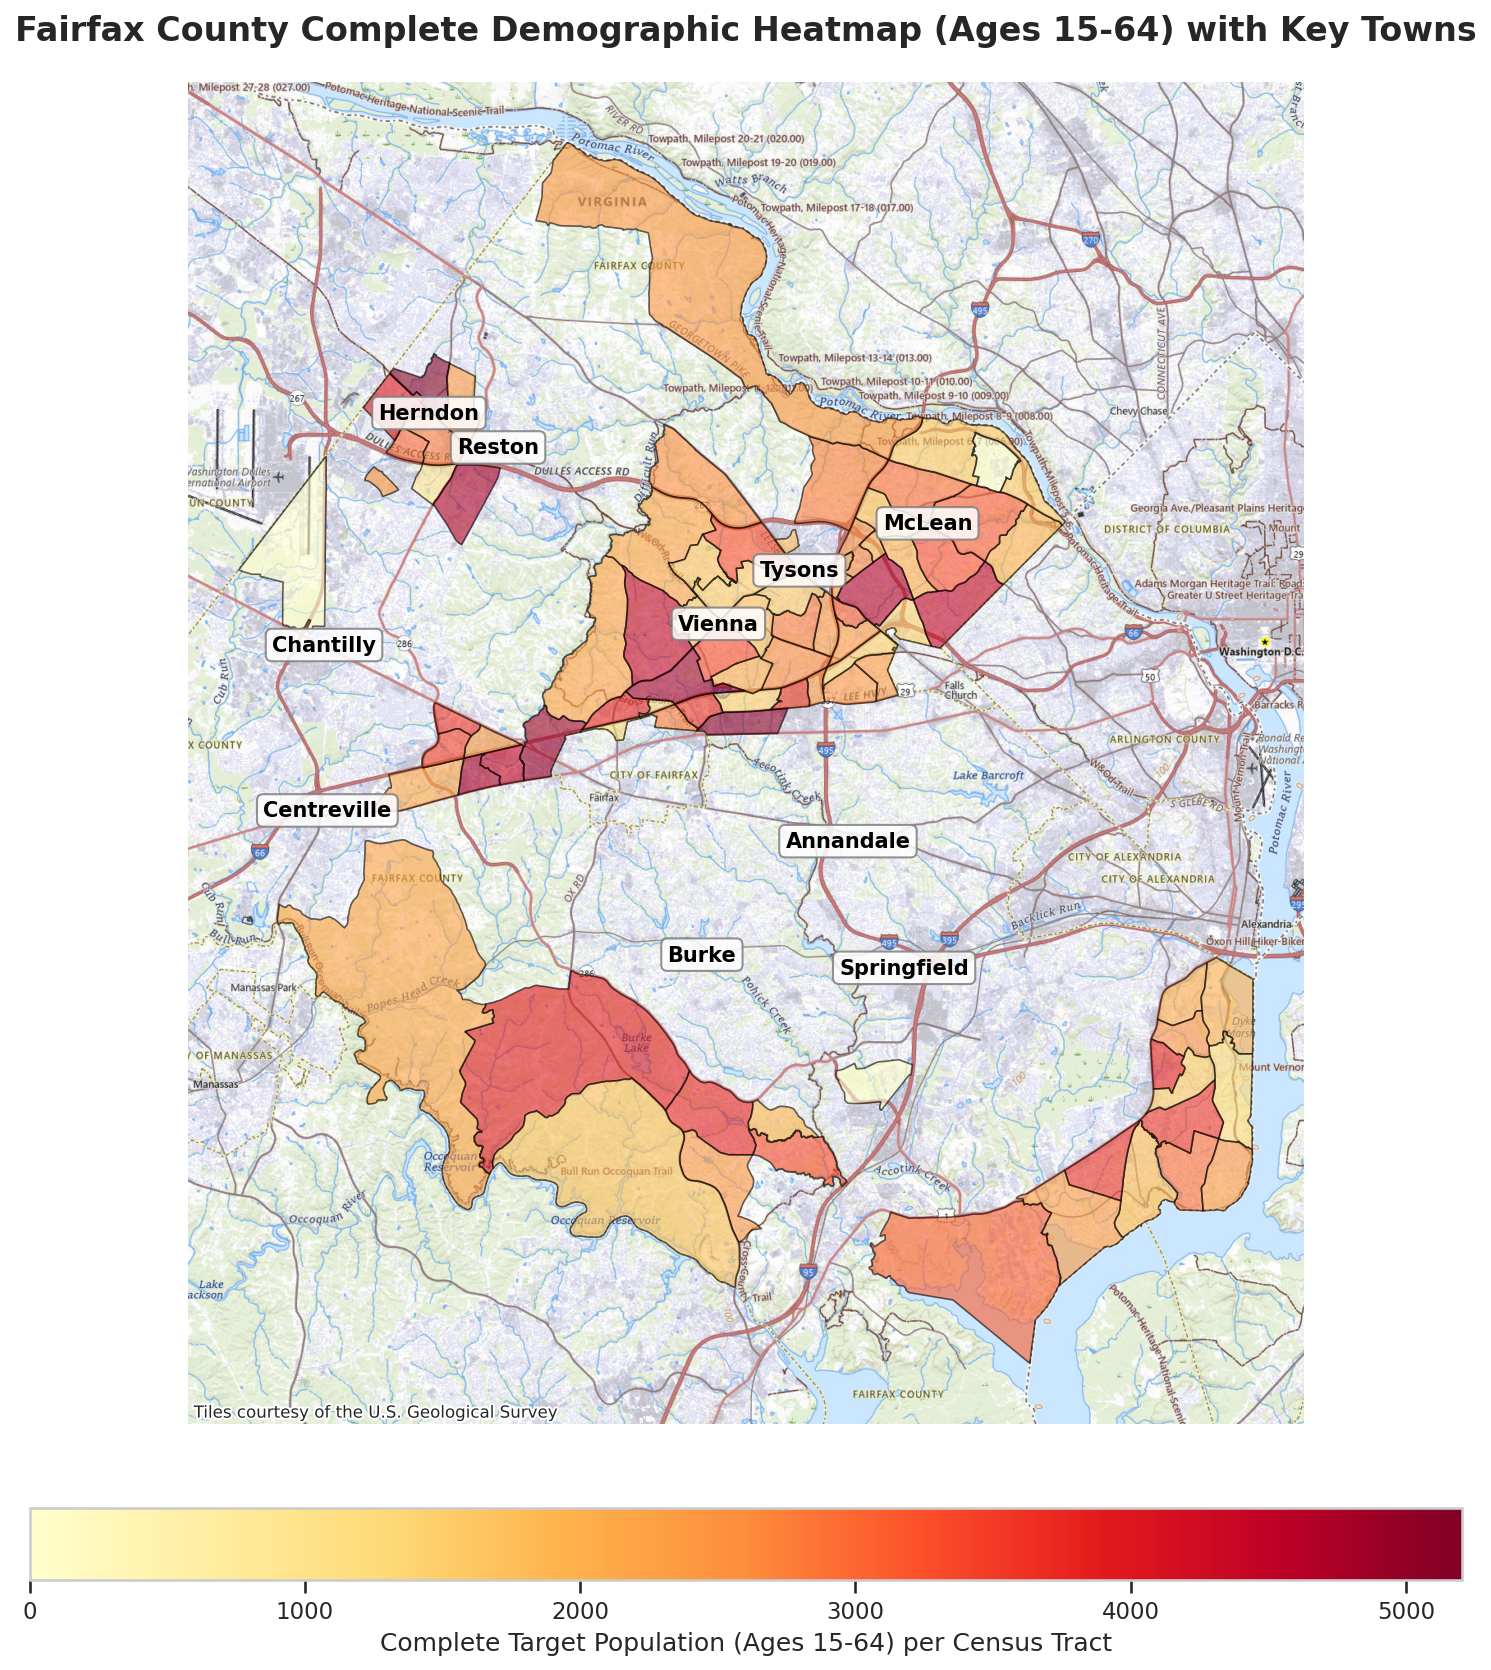

In [159]:
# 6. Render the verified heatmap with town labels
fig, ax = plt.subplots(figsize=(14, 12), dpi=150)
plot_gdf = merged_tracts_gdf.to_crs(epsg=3857)

plot_gdf.plot(
    column='Target_Age_Pop',
    cmap='YlOrRd',
    linewidth=0.8,
    edgecolor='black',
    legend=True,
    legend_kwds={
        'label': "Complete Target Population (Ages 15-64) per Census Tract",
        'orientation': "horizontal",
        'pad': 0.05,
        'shrink': 0.7
    },
    alpha=0.6,
    ax=ax
)

# Add the USGS Topo basemap
cx.add_basemap(ax, source=cx.providers.USGS.USTopo, zoom=12)

# Annotate the key towns in Fairfax County
transformer = pyproj.Transformer.from_crs("epsg:4326", "epsg:3857", always_xy=True)
towns = {
    "Reston": (-77.3572, 38.9586),
    "Herndon": (-77.3861, 38.9698),
    "Tysons": (-77.2311, 38.9186),
    "Vienna": (-77.2650, 38.9012),
    "McLean": (-77.1775, 38.9339),
    "Annandale": (-77.2108, 38.8304),
    "Springfield": (-77.1873, 38.7891),
    "Centreville": (-77.4286, 38.8404),
    "Chantilly": (-77.4300, 38.8943),
    "Burke": (-77.2719, 38.7934)
}

for town_name, (lon, lat) in towns.items():
    x, y = transformer.transform(lon, lat)
    ax.text(
        x, y, town_name,
        fontsize=10,
        fontweight='bold',
        ha='center',
        va='center',
        color='black',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=1, alpha=0.85)
    )

plt.title("Fairfax County Complete Demographic Heatmap (Ages 15-64) with Key Towns", fontsize=16, fontweight='bold', pad=20)
ax.set_axis_off()
plt.tight_layout()
plt.show()

**Summary: Fairfax Age Demographics**

**Primary Insight**
* Towns like Vienna, Herndon and Reston stand out with high numbers of targeted aged population.

**Strategic Takeaway**
* Diversity in age demographics is cruical to attracting customers once business is situated and Vienna stands out being in the middle of other populous cities

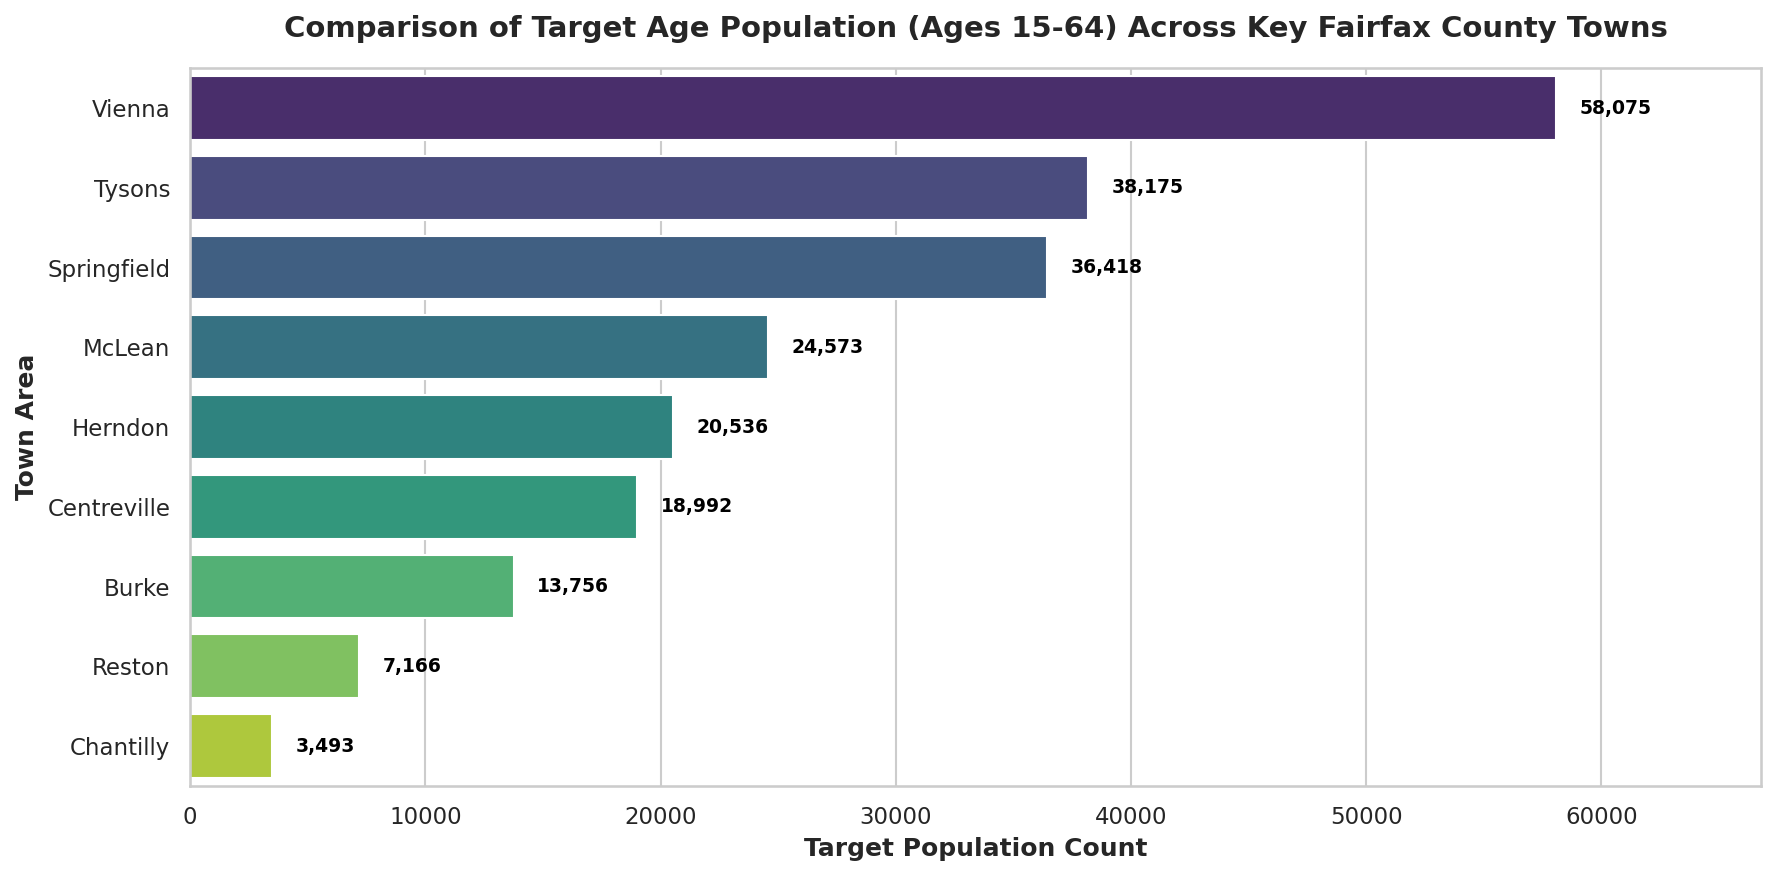

In [160]:
# 1. Coordinate data for the 10 key towns
town_coords = {
    "Reston": (-77.3572, 38.9586),
    "Herndon": (-77.3861, 38.9698),
    "Tysons": (-77.2311, 38.9186),
    "Vienna": (-77.2650, 38.9012),
    "McLean": (-77.1775, 38.9339),
    "Annandale": (-77.2108, 38.8304),
    "Springfield": (-77.1873, 38.7891),
    "Centreville": (-77.4286, 38.8404),
    "Chantilly": (-77.4300, 38.8943),
    "Burke": (-77.2719, 38.7934)
}

# 2. Convert town locations to a GeoDataFrame in EPSG:4326 and project to Web Mercator (EPSG:3857)
town_pts = []
for name, (lon, lat) in town_coords.items():
    town_pts.append({'Town': name, 'geometry': Point(lon, lat)})

towns_gdf = gpd.GeoDataFrame(town_pts, crs="EPSG:4326").to_crs("EPSG:3857")

# Project merged_tracts_gdf to EPSG:3857 to perform accurate distance calculations in meters
merged_tracts_3857 = merged_tracts_gdf.to_crs("EPSG:3857")

# 3. Associate each tract with the closest town using projected distance-based assignment
tract_centroids = merged_tracts_3857.copy()
tract_centroids['geometry'] = tract_centroids.geometry.centroid

assigned_towns = []
for idx, tract in tract_centroids.iterrows():
    distances = towns_gdf.distance(tract.geometry)
    closest_town_idx = distances.idxmin()
    closest_town_name = towns_gdf.loc[closest_town_idx, 'Town']
    assigned_towns.append(closest_town_name)

merged_tracts_3857['Assigned_Town'] = assigned_towns

# 4. Group by Assigned_Town to find total Target_Age_Pop
town_populations = merged_tracts_3857.groupby('Assigned_Town')['Target_Age_Pop'].sum().reset_index()
town_populations = town_populations.sort_values(by='Target_Age_Pop', ascending=False)

# 5. Render the Bar Chart
plt.figure(figsize=(12, 6), dpi=150)
sns.set_theme(style="whitegrid")

barplot = sns.barplot(
    data=town_populations,
    x='Target_Age_Pop',
    y='Assigned_Town',
    hue='Assigned_Town',
    palette='viridis',
    legend=False
)

# Annotate each bar with the population value
for index, row in town_populations.iterrows():
    barplot.text(
        row['Target_Age_Pop'] + 1000,
        town_populations.index.get_loc(index),
        f"{int(row['Target_Age_Pop']):,}",
        color='black',
        ha="left",
        va="center",
        fontweight='bold',
        fontsize=9
    )

plt.title("Comparison of Target Age Population (Ages 15-64) Across Key Fairfax County Towns", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Target Population Count", fontweight='bold')
plt.ylabel("Town Area", fontweight='bold')
plt.xlim(0, town_populations['Target_Age_Pop'].max() * 1.15)
plt.tight_layout()
plt.show()

**Summary: Chart representing age demographics**

**Primary Insight**
* Vienna has the highest number of 15-64 years old population with Tysons following it.
* Vienna is followed by Tysons which is closer in proximity, which might be startegic to locate a business accessible by people in both Vienna and Tysons.

In [161]:
# Cleaned income demographics by race dataframe

income_df = pd.read_csv("/content/ACSST5Y2024.S1903-Data.csv")
income_df.columns = income_df.loc[0]
income_df = income_df.iloc[1:].loc[:,~income_df.columns.str.startswith("Margin of Error", na = False)]
income_df.head()

,Geography,Geographic Area Name,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!White,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Black or African American,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!American Indian and Alaska Native,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Asian,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Native Hawaiian and Other Pacific Islander,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Some other race,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!Two or more races,...,Estimate!!Median income (dollars)!!FAMILY INCOME BY NUMBER OF EARNERS!!2 earners,Estimate!!Median income (dollars)!!FAMILY INCOME BY NUMBER OF EARNERS!!3 or more earners,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Not living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Not living alone,NaN
1,0400000US51,Virginia,3365732,2192706,629973,9847,201429,2007,103935,225835,...,144906,171227,56367,49502,43625,92702,65165,56490,106555,NaN
2,0500000US51059,"Fairfax County, Virginia",414101,233116,40758,1457,77278,255,21741,39496,...,218045,214004,98625,87861,81581,143482,109406,99778,155718,NaN
3,1400000US51059415100,Census Tract 4151; Fairfax County; Virginia,1118,837,36,0,17,0,56,172,...,"250,000+",200583,102315,109531,109063,-,101111,90250,-,NaN
4,1400000US51059415200,Census Tract 4152; Fairfax County; Virginia,1731,1301,55,0,98,0,109,168,...,238929,201528,81528,69000,68250,-,84896,84479,-,NaN
5,1400000US51059415300,Census Tract 4153; Fairfax County; Virginia,1692,1093,233,0,222,0,20,124,...,230227,162070,85700,85510,85520,-,103490,-,-,NaN


In [162]:
target_income_cencus_tract = [
 'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!15 to 24 years',
 'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!25 to 44 years',
 'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!45 to 64 years',
]

In [163]:
# 1. Filter age_df to only census tracts
income_df_tracts = income_df[income_df['Geographic Area Name'].str.contains('Census Tract', na=False)].copy()

# 2. Extract clean tract numbers using regex from the 'Geographic Area Name' column
income_df_tracts['Tract_Num'] = income_df_tracts['Geographic Area Name'].str.extract(r'Census Tract ([0-9.]+)')

# 3. Clean and convert each of your 10 target age groups to numeric values
for col in target_income_cencus_tract:
    income_df_tracts[col] = pd.to_numeric(income_df_tracts[col].astype(str).str.replace(',', ''), errors='coerce').fillna(0)

# 4. Explicitly sum all 10 columns to compute the verified total target population
income_df_tracts['Target_Income_Pop'] = income_df_tracts[target_income_cencus_tract
].sum(axis=1)

# 5. Standardize the tract IDs
def clean_tract_id(tract_str):
    if pd.isna(tract_str):
        return None
    try:
        val = float(tract_str)
        return f" {int(val * 100):06d}".strip()
    except ValueError:
        return None

income_df_tracts['TRACT_CE_CLEAN'] = income_df_tracts['Tract_Num'].apply(clean_tract_id)

# 6. Perform the final spatial merge
merged_tracts_income_gdf = fairfax_tracts_gdf.merge(income_df_tracts, left_on='TRACTCE', right_on='TRACT_CE_CLEAN', how='inner')

print(f"Successfully summed all 10 target age categories!")
print(f"Total Census Tracts Merged: {len(merged_tracts_income_gdf)}")
print(f"Total Demographics Population (15-64 years) across Fairfax: {merged_tracts_income_gdf['Target_Income_Pop'].sum():,}")

Successfully summed all 10 target age categories!
Total Census Tracts Merged: 84
Total Demographics Population (15-64 years) across Fairfax: 17,967,737.0


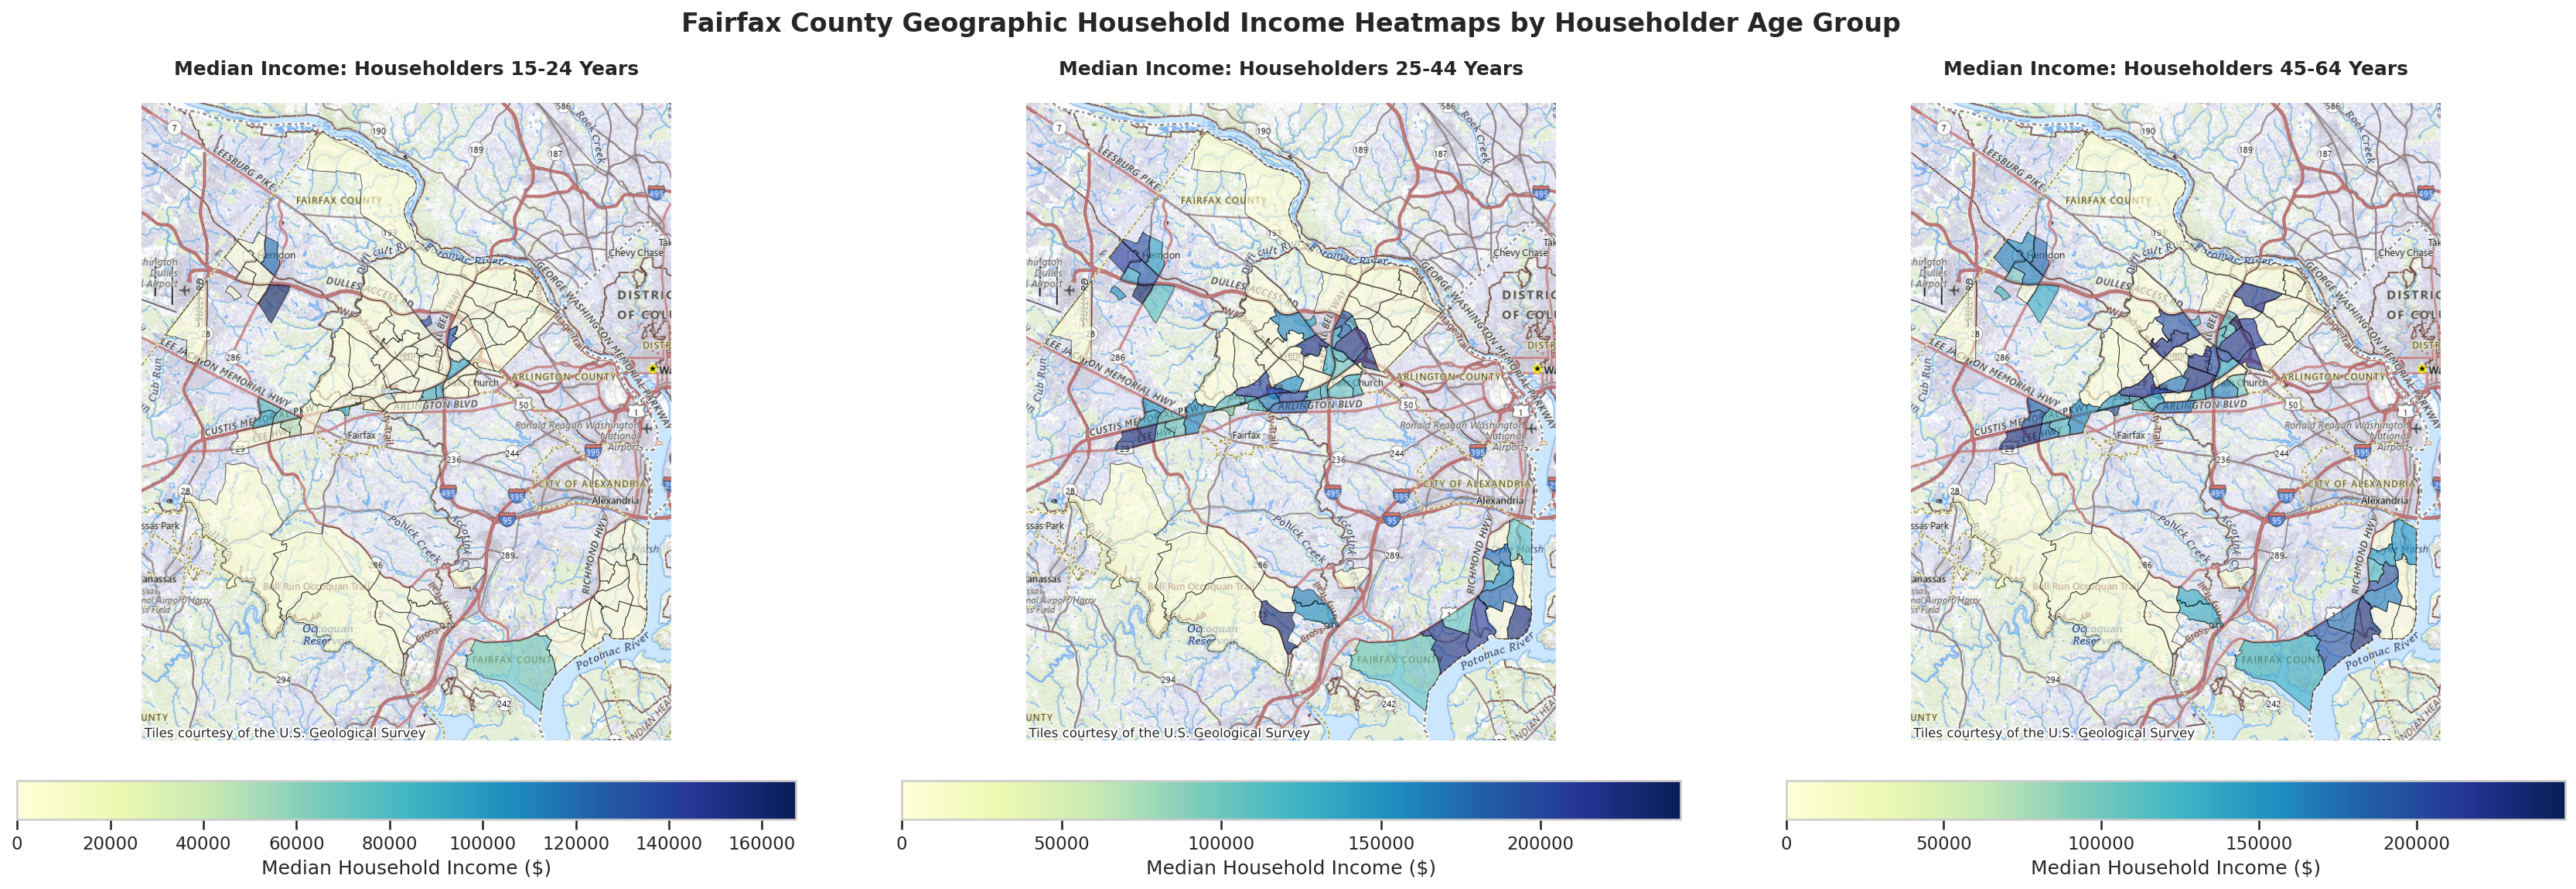

In [164]:
# Define the columns representing median household income for each age bracket

age_labels = ["Householders 15-24 Years", "Householders 25-44 Years", "Householders 45-64 Years"]

# Project the GeoDataFrame to Web Mercator (EPSG:3857) to accurately overlay the basemap
plot_income_gdf = merged_tracts_income_gdf.to_crs(epsg=3857)

# Set up a 1-row, 3-column figure layout
fig, axes = plt.subplots(1, 3, figsize=(24, 8), dpi=150)

for ax, col, label in zip(axes, target_income_cencus_tract, age_labels):
    # Plot the census tracts using a progressive sequential color map (e.g., Green-Blue)
    plot_income_gdf.plot(
        column=col,
        cmap='YlGnBu',
        linewidth=0.5,
        edgecolor='black',
        legend=True,
        legend_kwds={
            'label': "Median Household Income ($)",
            'orientation': "horizontal",
            'pad': 0.05,
            'shrink': 0.8
        },
        alpha=0.6,
        ax=ax,
        missing_kwds={'color': 'lightgrey', 'label': 'No Data'} # Handle missing survey values gracefully
    )

    # Add a clean basemap underneath the heatmap
    cx.add_basemap(ax, source=cx.providers.USGS.USTopo, zoom=11)

    # Customize subplots
    ax.set_title(f"Median Income: {label}", fontsize=12, fontweight='bold')
    ax.set_axis_off()

plt.suptitle("Fairfax County Geographic Household Income Heatmaps by Householder Age Group", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


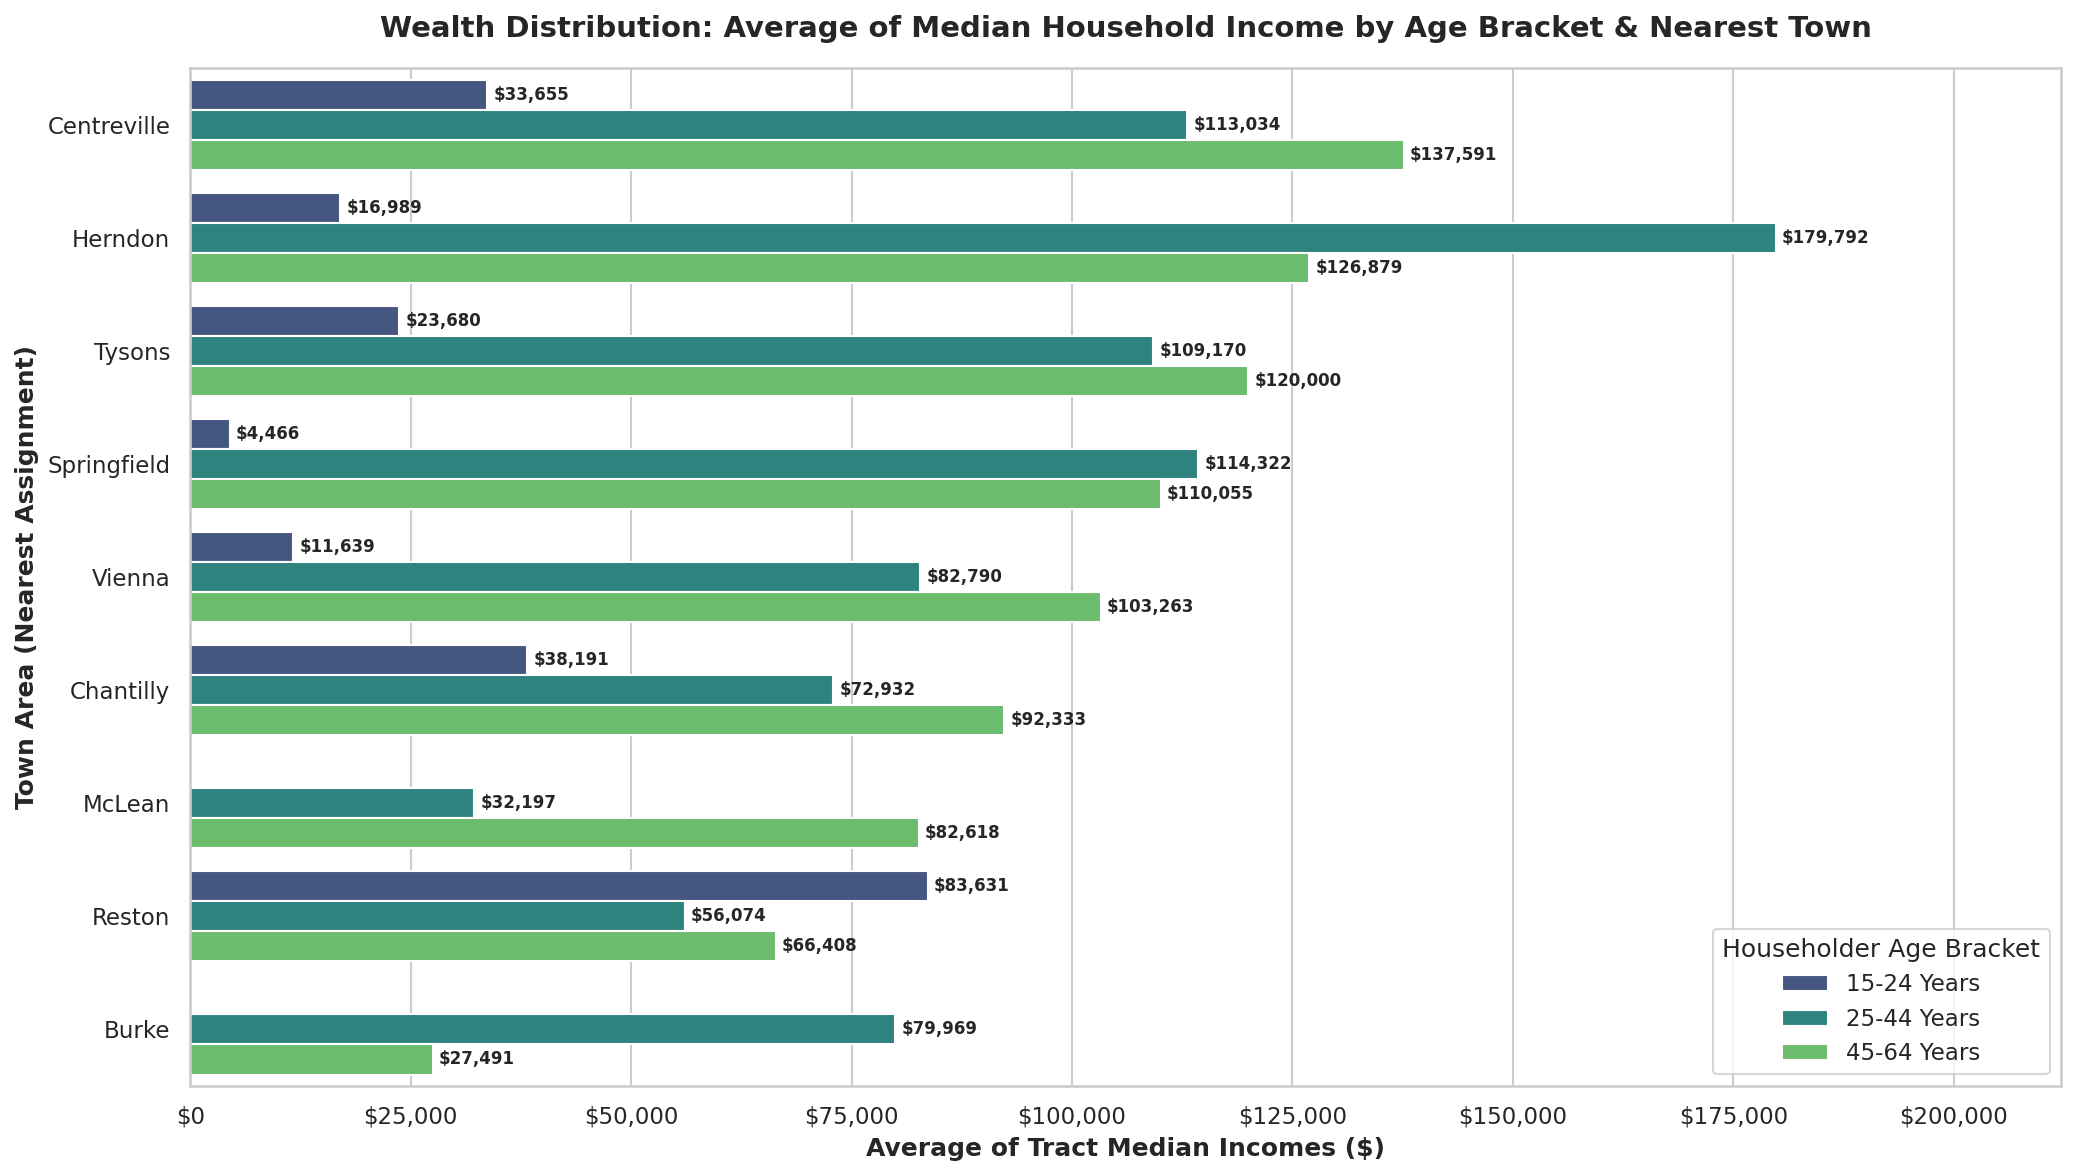

In [166]:
# Coordinate data for key towns
town_coords = {
    "Reston": (-77.3572, 38.9586),
    "Herndon": (-77.3861, 38.9698),
    "Tysons": (-77.2311, 38.9186),
    "Vienna": (-77.2650, 38.9012),
    "McLean": (-77.1775, 38.9339),
    "Annandale": (-77.2108, 38.8304),
    "Springfield": (-77.1873, 38.7891),
    "Centreville": (-77.4286, 38.8404),
    "Chantilly": (-77.43, 38.8943),
    "Burke": (-77.2719, 38.7934)
}

# Build towns GeoDataFrame and project to Web Mercator
town_pts = [{'Town': name, 'geometry': Point(lon, lat)} for name, (lon, lat) in town_coords.items()]
towns_gdf = gpd.GeoDataFrame(town_pts, crs="EPSG:4326").to_crs("EPSG:3857")

# Project demographic boundaries to EPSG:3857
merged_income_3857 = merged_tracts_income_gdf.to_crs("EPSG:3857")

# Associate each tract centroid with the nearest town
tract_centroids = merged_income_3857.copy()
tract_centroids['geometry'] = tract_centroids.geometry.centroid

assigned_towns = []
for idx, tract in tract_centroids.iterrows():
    distances = towns_gdf.distance(tract.geometry)
    closest_idx = distances.idxmin()
    assigned_towns.append(towns_gdf.loc[closest_idx, 'Town'])

merged_income_3857['Assigned_Town'] = assigned_towns

# Aggregate income (mean of medians) per town
town_wealth = merged_income_3857.groupby('Assigned_Town')[target_income_cencus_tract].mean().reset_index()

# Map target demographic categories
age_labels_map = {
    target_income_cencus_tract[0]: "15-24 Years",
    target_income_cencus_tract[1]: "25-44 Years",
    target_income_cencus_tract[2]: "45-64 Years"
}

# Reshape dataset from wide to long format
town_wealth_melted = pd.melt(
    town_wealth,
    id_vars=['Assigned_Town'],
    value_vars=target_income_cencus_tract,
    var_name='Age_Group_Raw',
    value_name='Average_Median_Income'
)
town_wealth_melted['Age Group'] = town_wealth_melted['Age_Group_Raw'].map(age_labels_map)

# Sort towns using the peak income group (45-64 Years)
sort_order = town_wealth.sort_values(by=target_income_cencus_tract[2], ascending=False)['Assigned_Town'].tolist()

# Plot wealth distributions
plt.figure(figsize=(14, 8), dpi=150)
sns.set_theme(style="whitegrid")

barplot = sns.barplot(
    data=town_wealth_melted,
    x='Average_Median_Income',
    y='Assigned_Town',
    hue='Age Group',
    order=sort_order,
    palette='viridis'
)

# Apply dollar sign format to X-axis ticks
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"${int(x):,}"))

# Annotate exact wealth totals directly on the bar edges
for container in barplot.containers:
    widths = [rect.get_width() for rect in container]
    labels = [f"${int(w):,}" if (pd.notna(w) and w > 0) else "" for w in widths]
    barplot.bar_label(container, labels=labels, label_type='edge', fontsize=8, padding=3, fontweight='bold')

# Finalize layout labels
plt.title("Wealth Distribution: Average of Median Household Income by Age Bracket & Nearest Town", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Average of Tract Median Incomes ($)", fontweight='bold')
plt.ylabel("Town Area (Nearest Assignment)", fontweight='bold')
plt.legend(title="Householder Age Bracket", loc="lower right")
plt.xlim(0, town_wealth[target_income_cencus_tract].max().max() * 1.18)
plt.tight_layout()
plt.show()

### **Summary: Income Distribution Across Key Fairfax County Towns**

**Primary Insight**
* **Top-Earning Suburbs:** Burke and Centreville stand out with the highest average median household incomes among established professionals (**Ages 45–64**), both exceeding **$137,000** annually.

* **Early-Career Wealth:** Reston and Tysons demonstrate strong entry-level financial potential, maintaining competitive household earnings for young professionals (**Ages 15–24**) compared to more historically suburban areas.
* **Middle-Age Consistency:** Across almost all towns, the prime working age bracket (**Ages 25–44**) displays highly consistent buying power, consistently hovering between **$80,000** and **$110,000**.

**Strategic Takeaway**
* **Business Location Targeting:** If you are establishing premium services or luxury brands, locating near **Burke or Centreville** positions your business near peak-earning older households. However, if you target high-density, trendy consumer segments with high disposable income, **Tysons and Reston** provide the optimal balance of population size and strong youth/mid-career income profiles.